# Optimización Logística, Análisis de Ventas y Nivel de Servicio en el E-Commerce Olist

## Integrantes

- Ferney Morales
- Julian GUerra
- Nicolas Samaca

## Tema

Visualización avanzada aplicada al análisis logístico, comercial y de satisfacción del cliente en el comercio electrónico.

## Dataset

**Brazilian E-Commerce Public Dataset by Olist** - datos públicos y reales publicados en Kaggle.

# 1. Contexto del proyecto

## ¿Cuál es el problema?

La plataforma presenta demoras imprevistas en los despachos logísticos entre diferentes estados y variaciones en los costos de flete. Estas situaciones pueden ocasionar cancelaciones de pedidos y calificaciones bajas por parte de los compradores.

## ¿A quién afecta?

El problema afecta a los gerentes de logística y operaciones de despacho, a los vendedores afiliados que pueden perder reputación dentro de la plataforma y a los clientes finales que reciben sus pedidos tarde o experimentan incumplimientos.

## ¿Qué busca responder el análisis?

El análisis busca identificar las rutas y los estados con mayores retrasos frente a la fecha estimada de entrega, estudiar el impacto del costo del flete y del tiempo de envío sobre la calificación del cliente, y reconocer las categorías y los métodos de pago más relacionados con cancelaciones o pedidos no entregados.

# 2. Preguntas concretas de negocio

1. **Logística y cumplimiento:** ¿Cuál es la diferencia entre el tiempo estimado y el tiempo real de entrega por estado del cliente (`customer_state`), y qué porcentaje de pedidos llega con retraso?
2. **Satisfacción del cliente:** ¿Cómo se relacionan el tiempo de entrega y el valor del flete con la calificación del cliente (`review_score`) de 1 a 5 estrellas?
3. **Comportamiento comercial:** ¿Cuáles son las categorías de productos que generan mayores ingresos y cuáles presentan el ticket promedio más alto?
4. **Medios de pago y riesgo:** ¿Qué métodos de pago (`credit_card`, `boleto` y `voucher`) concentran el mayor volumen y cuál presenta la mayor tasa de pedidos cancelados o no entregados?

# 3. Alcance de nuestra contribución

El notebook integra las tres temáticas seleccionadas: **PySpark batch**, **PySpark Structured Streaming** y **Visualización Avanzada**. Cada componente utiliza las mismas preguntas de negocio y el mismo dataset Olist para mantener coherencia entre los resultados.

La contribución comprende lectura distribuida, diagnóstico de calidad, joins, `groupBy`, Spark SQL, métricas vectorizadas, histogramas, mapas de calor, visualizaciones interactivas, simulación de micro-lotes, actualización de métricas en vivo, validaciones cruzadas, conclusiones y recomendaciones.

# 4. Preparación del entorno

Todas las dependencias externas del notebook y del dashboard están centralizadas en `requirements.txt`. Ejecute la siguiente celda una sola vez si el entorno todavía no tiene las librerías instaladas.


In [1]:
# Descomente para instalar todas las dependencias del proyecto.
# %pip install -r requirements.txt


In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
pio.renderers.default = "notebook_connected"

# El notebook busca la carpeta del dataset en varias ubicaciones habituales.
DATA_CANDIDATES = [
    Path(r"C:\Users\nicos\Documents\Codex\2026-09-05\re\outputs\olist_depurado\tablas_fuente_limpias"),
    Path("archive"),
    Path("../archive"),
    
    Path(r"C:\Users\nicos\Downloads\archive"),
]
DATA_DIR = next((p.resolve() for p in DATA_CANDIDATES if p.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "No se encontró la carpeta 'archive'. Ajuste DATA_CANDIDATES con la ruta del dataset Olist."
    )

print(f"Carpeta de datos: {DATA_DIR}")

Carpeta de datos: C:\Users\nicos\Documents\Codex\2026-09-05\re\outputs\olist_depurado\tablas_fuente_limpias


## 4.1 Auditoría y depuración previa del dataset

Los archivos originales se conservaron sin modificaciones y el análisis utiliza copias depuradas. Las decisiones principales fueron:

- eliminar **261.831 duplicados exactos** de geolocalización y crear una referencia única por código postal;
- etiquetar **610 productos sin categoría** como `unknown`, sin inventar pesos o dimensiones;
- conservar **547 pedidos con múltiples reseñas** y promediar su calificación únicamente al construir la tabla analítica;
- cambiar **3 métodos de pago `not_defined`** a `unknown` y marcar **2 registros con cuotas no válidas**;
- marcar cronologías imposibles y excluirlas solo de las métricas de duración;
- agregar ítems, pagos y reseñas antes de los joins para evitar duplicar ingresos o pedidos.

No se eliminaron cancelaciones, pedidos no entregados, entregas tardías, comentarios vacíos ni valores extremos, porque forman parte de las preguntas del proyecto.

# 5. Carga de datos y diagnóstico de calidad

Se cargan únicamente las tablas necesarias para responder las preguntas. La tabla de geolocalización no se utiliza porque el análisis solicitado se realiza a nivel de estado y no requiere coordenadas.

In [3]:
date_cols_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv", parse_dates=date_cols_orders)
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
payments = pd.read_csv(DATA_DIR / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv")
translations = pd.read_csv(DATA_DIR / "product_category_name_translation.csv", encoding="utf-8-sig")

tables = {
    "orders": orders,
    "customers": customers,
    "items": items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "sellers": sellers,
    "translations": translations,
}

quality = pd.DataFrame(
    [
        {
            "tabla": name,
            "filas": len(df),
            "columnas": df.shape[1],
            "nulos_totales": int(df.isna().sum().sum()),
            "duplicados_exactos": int(df.duplicated().sum()),
        }
        for name, df in tables.items()
    ]
).sort_values("filas", ascending=False)

display(quality.reset_index(drop=True))

,tabla,filas,columnas,nulos_totales,duplicados_exactos
0,items,112650,7,0,0
1,payments,103886,7,2,0
2,customers,99441,5,0,0
3,orders,99441,12,4908,0
4,reviews,99224,7,145932,0
5,products,32951,11,1838,0
6,sellers,3095,4,0,0
7,translations,71,2,0,0


# 6. Limpieza y preparación de variables

Decisiones aplicadas:

- Se conserva una fila por pedido en la tabla analítica principal para evitar duplicar ventas al unir ítems, pagos o reseñas.
- Cuando un pedido tiene más de una reseña se usa el promedio de `review_score`.
- Los precios y fletes se agregan por pedido antes de unirlos con las fechas logísticas.
- Los cálculos de tiempo se realizan solo cuando existen las fechas requeridas.
- Un pedido se considera **tardío** cuando la entrega real ocurre después de la fecha estimada.
- Se muestran por separado la tasa de cancelación y la tasa de pedidos cuyo estado final es distinto de `delivered`.

In [4]:
# Agregaciones a nivel de pedido para evitar relaciones muchos-a-muchos.
review_order = (
    reviews.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"), review_records=("review_id", "count"))
)

item_order = (
    items.groupby("order_id", as_index=False)
    .agg(
        product_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("order_item_id", "count"),
        seller_count=("seller_id", "nunique"),
    )
)

payment_order = (
    payments.groupby("order_id", as_index=False)
    .agg(payment_value=("payment_value", "sum"), payment_records=("payment_sequential", "count"))
)

base = (
    orders.merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left",
        validate="many_to_one",
    )
    .merge(item_order, on="order_id", how="left", validate="one_to_one")
    .merge(payment_order, on="order_id", how="left", validate="one_to_one")
    .merge(review_order, on="order_id", how="left", validate="one_to_one")
)

base["delivery_days"] = (
    base["order_delivered_customer_date"] - base["order_purchase_timestamp"]
).dt.total_seconds() / 86_400
base["estimated_days"] = (
    base["order_estimated_delivery_date"] - base["order_purchase_timestamp"]
).dt.total_seconds() / 86_400
base["delay_days"] = (
    base["order_delivered_customer_date"] - base["order_estimated_delivery_date"]
).dt.total_seconds() / 86_400
base["dispatch_days"] = (
    base["order_delivered_carrier_date"] - base["order_approved_at"]
).dt.total_seconds() / 86_400

# Las secuencias temporales imposibles se conservan para auditoría, pero no se
# utilizan en promedios, correlaciones ni porcentajes logísticos.
timeline_flag_cols = [
    "flag_approval_before_purchase",
    "flag_carrier_before_approval",
    "flag_customer_before_carrier",
]
available_timeline_flags = [c for c in timeline_flag_cols if c in base.columns]
if available_timeline_flags:
    invalid_timeline = base[available_timeline_flags].fillna(False).any(axis=1)
    base.loc[
        invalid_timeline,
        ["delivery_days", "delay_days", "dispatch_days"],
    ] = np.nan

base["late_delivery"] = base["delay_days"].gt(0).astype("boolean")
base.loc[base["delay_days"].isna(), "late_delivery"] = pd.NA
base["cancelled"] = base["order_status"].eq("canceled")
base["not_delivered"] = base["order_status"].ne("delivered")
base["freight_ratio"] = np.where(
    (base["product_value"] + base["freight_value"]) > 0,
    base["freight_value"] / (base["product_value"] + base["freight_value"]),
    np.nan,
)

delivered = base.loc[
    base["order_status"].eq("delivered")
    & base["delivery_days"].notna()
    & base["delay_days"].notna()
].copy()

integrity = pd.DataFrame(
    {
        "indicador": [
            "Pedidos originales",
            "Pedidos únicos en la base analítica",
            "Pedidos entregados con fechas válidas",
            "Pedidos con reseña",
            "Pedidos con información de ítems",
        ],
        "valor": [
            len(orders),
            base["order_id"].nunique(),
            len(delivered),
            base["review_score"].notna().sum(),
            base["product_value"].notna().sum(),
        ],
    }
)
display(integrity)

,indicador,valor
0,Pedidos originales,99441
1,Pedidos únicos en la base analítica,99441
2,Pedidos entregados con fechas válidas,95097
3,Pedidos con reseña,98673
4,Pedidos con información de ítems,98666


# 7. Métricas vectorizadas con NumPy

Las operaciones se realizan sobre arreglos de NumPy, sin ciclos fila por fila. Esto permite resumir el comportamiento logístico de forma eficiente.

In [5]:
delivery_np = delivered["delivery_days"].to_numpy(dtype=float)
delay_np = delivered["delay_days"].to_numpy(dtype=float)
freight_np = delivered["freight_value"].dropna().to_numpy(dtype=float)
review_np = delivered["review_score"].dropna().to_numpy(dtype=float)

numpy_metrics = pd.DataFrame(
    {
        "métrica": [
            "Tiempo medio de entrega (días)",
            "Mediana de entrega (días)",
            "Percentil 95 de entrega (días)",
            "Retraso medio frente a la fecha estimada (días)",
            "Pedidos entregados tarde (%)",
            "Flete mediano por pedido (R$)",
            "Calificación media",
        ],
        "valor": [
            np.nanmean(delivery_np),
            np.nanmedian(delivery_np),
            np.nanpercentile(delivery_np, 95),
            np.nanmean(delay_np),
            np.mean(delay_np > 0) * 100,
            np.nanmedian(freight_np),
            np.nanmean(review_np),
        ],
    }
)
display(numpy_metrics.round(2))

,métrica,valor
0,Tiempo medio de entrega (días),12.62
1,Mediana de entrega (días),10.27
2,Percentil 95 de entrega (días),29.40
3,Retraso medio frente a la fecha estimada (días),-11.13
4,Pedidos entregados tarde (%),8.19
5,Flete mediano por pedido (R$),17.16
6,Calificación media,4.15


# 8. Visualizaciones que responden las preguntas

## 8.1 Logística y cumplimiento por estado

La diferencia se define como `fecha real de entrega - fecha estimada`. Un valor positivo representa retraso; un valor negativo indica que el pedido llegó antes de lo previsto.

In [6]:
state_logistics = (
    delivered.groupby("customer_state", as_index=False)
    .agg(
        pedidos=("order_id", "nunique"),
        tiempo_real_dias=("delivery_days", "mean"),
        tiempo_estimado_dias=("estimated_days", "mean"),
        diferencia_media_dias=("delay_days", "mean"),
        porcentaje_tarde=("late_delivery", "mean"),
    )
)
state_logistics["porcentaje_tarde"] *= 100
state_logistics = state_logistics.sort_values("porcentaje_tarde", ascending=False)

display(state_logistics.round(2))

fig_state = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Porcentaje de pedidos tardíos", "Diferencia media: real - estimada"),
)
fig_state.add_trace(
    go.Bar(
        x=state_logistics["customer_state"],
        y=state_logistics["porcentaje_tarde"],
        marker_color="#E45756",
        hovertemplate="Estado %{x}<br>Tardíos: %{y:.2f}%<extra></extra>",
    ),
    row=1,
    col=1,
)
fig_state.add_trace(
    go.Bar(
        x=state_logistics["customer_state"],
        y=state_logistics["diferencia_media_dias"],
        marker_color="#4C78A8",
        hovertemplate="Estado %{x}<br>Diferencia: %{y:.2f} días<extra></extra>",
    ),
    row=1,
    col=2,
)
fig_state.update_layout(
    title="Cumplimiento logístico por estado del cliente",
    height=520,
    showlegend=False,
    template="plotly_white",
)
fig_state.update_xaxes(title_text="Estado")
fig_state.update_yaxes(title_text="Pedidos tardíos (%)", row=1, col=1)
fig_state.update_yaxes(title_text="Días", row=1, col=2)
fig_state.show(config={"displaylogo": False})

,customer_state,pedidos,tiempo_real_dias,tiempo_estimado_dias,diferencia_media_dias,porcentaje_tarde
1,AL,393,24.38,32.62,-8.24,23.66
9,MA,705,21.66,30.53,-8.86,20.00
16,PI,469,19.59,30.09,-10.50,16.20
5,CE,1260,21.39,31.41,-10.02,15.56
24,SE,333,21.59,30.87,-9.28,15.32
4,BA,3210,19.38,29.44,-10.05,14.08
18,RJ,12212,15.38,26.34,-10.96,13.59
26,TO,270,17.78,29.18,-11.40,12.96
21,RR,40,29.85,46.35,-16.50,12.50
7,ES,1968,15.85,25.60,-9.76,12.30


### Rutas entre estados

Una ruta se representa como el par `seller_state → customer_state`. Como un pedido puede incluir vendedores de varios estados, primero se conservan pares únicos pedido-ruta. Para evitar conclusiones basadas en pocos casos, se muestran rutas con al menos 50 pedidos entregados.

In [7]:
order_routes = (
    items[["order_id", "seller_id"]]
    .drop_duplicates()
    .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
    .merge(
        delivered[["order_id", "customer_state", "delay_days", "late_delivery", "delivery_days"]],
        on="order_id",
        how="inner",
    )
    .drop_duplicates(["order_id", "seller_state", "customer_state"])
)

route_logistics = (
    order_routes.groupby(["seller_state", "customer_state"], as_index=False)
    .agg(
        pedidos=("order_id", "nunique"),
        retraso_medio_dias=("delay_days", "mean"),
        porcentaje_tarde=("late_delivery", "mean"),
    )
)
route_logistics["porcentaje_tarde"] *= 100
route_reliable = route_logistics.query("pedidos >= 50").sort_values(
    ["porcentaje_tarde", "pedidos"], ascending=[False, False]
)
display(route_reliable.head(15).round(2))

top_seller_states = (
    order_routes.groupby("seller_state")["order_id"].nunique().nlargest(8).index
)
route_heat = (
    route_logistics[route_logistics["seller_state"].isin(top_seller_states)]
    .pivot(index="seller_state", columns="customer_state", values="porcentaje_tarde")
)
fig_route = px.imshow(
    route_heat,
    color_continuous_scale="YlOrRd",
    labels={"x": "Estado del cliente", "y": "Estado del vendedor", "color": "% tardío"},
    title="Mapa de calor interactivo: retrasos por ruta entre estados",
    aspect="auto",
)
fig_route.update_layout(height=480, template="plotly_white")
fig_route.show(config={"displaylogo": False})

,seller_state,customer_state,pedidos,retraso_medio_dias,porcentaje_tarde
140,MA,SP,118,-8.74,26.27
384,SP,AL,254,-7.34,25.98
283,RJ,CE,54,-5.74,22.22
392,SP,MA,482,-8.56,21.78
399,SP,PI,326,-9.82,18.40
255,PR,BA,143,-9.57,16.78
407,SP,SE,206,-8.64,16.50
151,MG,MA,64,-10.70,15.62
401,SP,RJ,8096,-10.05,15.56
388,SP,CE,954,-10.12,15.51


## 8.2 Tiempo, flete y satisfacción del cliente

Primero se observa la distribución de los tiempos de entrega. Para que los valores extremos no oculten el patrón principal, el histograma se limita al percentil 99, sin eliminar esos registros de los demás cálculos.

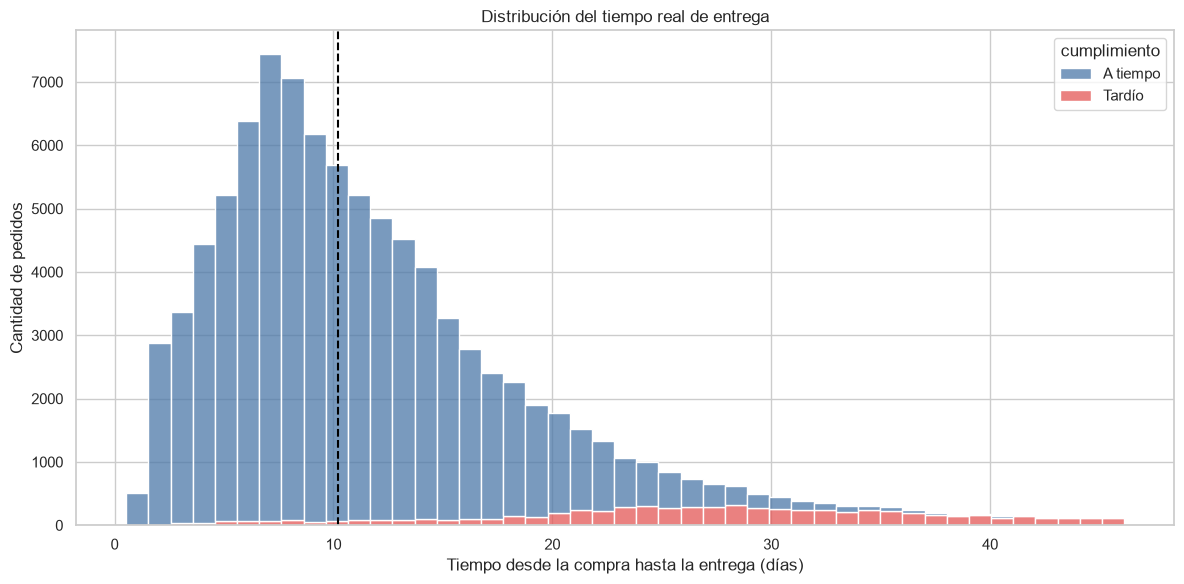

In [8]:
p99_delivery = delivered["delivery_days"].quantile(0.99)
hist_data = delivered.loc[delivered["delivery_days"] <= p99_delivery].copy()
hist_data["cumplimiento"] = np.where(hist_data["late_delivery"], "Tardío", "A tiempo")

plt.figure(figsize=(12, 6))
sns.histplot(
    data=hist_data,
    x="delivery_days",
    hue="cumplimiento",
    bins=45,
    multiple="stack",
    palette={"A tiempo": "#4C78A8", "Tardío": "#E45756"},
)
plt.axvline(hist_data["delivery_days"].median(), color="black", linestyle="--", label="Mediana")
plt.title("Distribución del tiempo real de entrega")
plt.xlabel("Tiempo desde la compra hasta la entrega (días)")
plt.ylabel("Cantidad de pedidos")
plt.tight_layout()
plt.show()

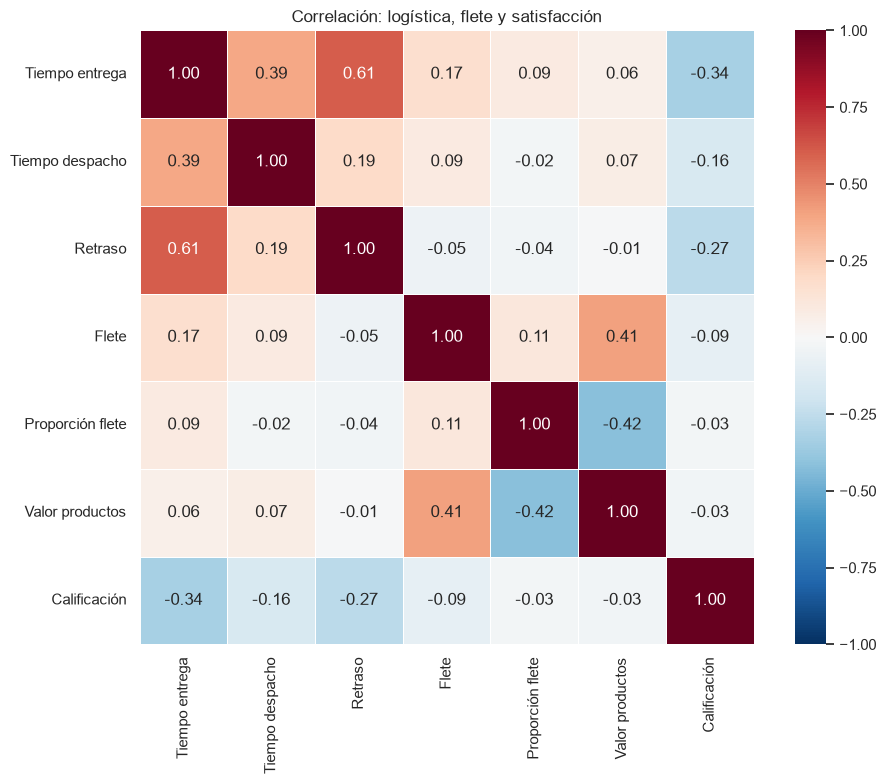

In [9]:
corr_cols = [
    "delivery_days",
    "dispatch_days",
    "delay_days",
    "freight_value",
    "freight_ratio",
    "product_value",
    "review_score",
]
corr_labels = {
    "delivery_days": "Tiempo entrega",
    "dispatch_days": "Tiempo despacho",
    "delay_days": "Retraso",
    "freight_value": "Flete",
    "freight_ratio": "Proporción flete",
    "product_value": "Valor productos",
    "review_score": "Calificación",
}
corr = delivered[corr_cols].corr(method="pearson").rename(
    index=corr_labels, columns=corr_labels
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
)
plt.title("Correlación: logística, flete y satisfacción")
plt.tight_layout()
plt.show()

In [10]:
# Muestra reproducible para mantener la interacción fluida.
scatter_data = delivered.dropna(
    subset=["delivery_days", "freight_value", "review_score", "customer_state"]
).copy()
scatter_data = scatter_data[
    (scatter_data["delivery_days"] <= scatter_data["delivery_days"].quantile(0.99))
    & (scatter_data["freight_value"] <= scatter_data["freight_value"].quantile(0.99))
]
if len(scatter_data) > 6000:
    scatter_data = scatter_data.sample(6000, random_state=42)

fig_scatter = px.scatter(
    scatter_data,
    x="delivery_days",
    y="freight_value",
    color="review_score",
    color_continuous_scale="RdYlGn",
    hover_data=["customer_state", "delay_days", "product_value"],
    opacity=0.55,
    labels={
        "delivery_days": "Tiempo de entrega (días)",
        "freight_value": "Flete por pedido (R$)",
        "review_score": "Calificación",
    },
    title="Relación interactiva entre tiempo de entrega, flete y calificación",
)
fig_scatter.update_layout(height=560, template="plotly_white")
fig_scatter.show(config={"displaylogo": False})

## 8.3 Categorías con mayores ingresos y ticket promedio

El ingreso corresponde a la suma del precio de los productos, sin incluir flete. El ticket promedio se calcula por pedido dentro de cada categoría. Para el ranking de ticket se exigen al menos 100 pedidos por categoría y así se evita destacar categorías con muy pocos casos.

In [11]:
item_category = (
    items.merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left",
        validate="many_to_one",
    )
    .merge(translations, on="product_category_name", how="left", validate="many_to_one")
)
item_category["category"] = item_category["product_category_name_english"].fillna(
    item_category["product_category_name"]
).fillna("sin_categoria")

category_order = (
    item_category.groupby(["category", "order_id"], as_index=False)
    .agg(category_order_value=("price", "sum"), category_freight=("freight_value", "sum"))
)
category_stats = (
    category_order.groupby("category", as_index=False)
    .agg(
        ingresos=("category_order_value", "sum"),
        pedidos=("order_id", "nunique"),
        ticket_promedio=("category_order_value", "mean"),
        flete_promedio=("category_freight", "mean"),
    )
)

top_revenue = category_stats.nlargest(12, "ingresos").sort_values("ingresos")
top_ticket = (
    category_stats.query("pedidos >= 100")
    .nlargest(12, "ticket_promedio")
    .sort_values("ticket_promedio")
)

fig_categories = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Categorías con mayores ingresos", "Mayor ticket promedio (mínimo 100 pedidos)"),
    horizontal_spacing=0.20,
)
fig_categories.add_trace(
    go.Bar(
        x=top_revenue["ingresos"],
        y=top_revenue["category"],
        orientation="h",
        marker_color="#59A14F",
        hovertemplate="%{y}<br>Ingresos: R$ %{x:,.2f}<extra></extra>",
    ),
    row=1,
    col=1,
)
fig_categories.add_trace(
    go.Bar(
        x=top_ticket["ticket_promedio"],
        y=top_ticket["category"],
        orientation="h",
        marker_color="#F28E2B",
        hovertemplate="%{y}<br>Ticket: R$ %{x:,.2f}<extra></extra>",
    ),
    row=1,
    col=2,
)
fig_categories.update_layout(
    title="Desempeño comercial por categoría",
    height=650,
    showlegend=False,
    template="plotly_white",
    margin=dict(l=180, r=30, t=100, b=50),
)
fig_categories.update_xaxes(title_text="Ingresos (R$)", row=1, col=1)
fig_categories.update_xaxes(title_text="Ticket promedio (R$)", row=1, col=2)
fig_categories.show(config={"displaylogo": False})

display(category_stats.nlargest(10, "ingresos").round(2))

,category,ingresos,pedidos,ticket_promedio,flete_promedio
43,health_beauty,"1,258,681.34",8836,142.45,20.66
73,watches_gifts,"1,205,005.68",5624,214.26,17.88
7,bed_bath_table,"1,036,988.68",9417,110.12,21.74
67,sports_leisure,"988,048.97",7720,127.99,21.84
15,computers_accessories,"911,954.32",6689,136.34,22.02
39,furniture_decor,"729,762.49",6449,113.16,26.79
20,cool_stuff,"635,290.85",3632,174.91,23.14
49,housewares,"632,248.66",5884,107.45,24.84
5,auto,"592,720.11",3897,152.10,23.78
42,garden_tools,"485,256.46",3518,137.94,28.13


## 8.4 Medios de pago y riesgo

Se estudian `credit_card`, `boleto` y `voucher`. Un pedido con pago mixto puede aparecer en más de un método; dentro de cada método, cada pedido se cuenta una sola vez. La tasa de no entrega incluye todos los estados diferentes de `delivered`, mientras que la tasa de cancelación usa únicamente `canceled`.

In [12]:
selected_methods = ["credit_card", "boleto", "voucher"]
payment_by_order_type = (
    payments[payments["payment_type"].isin(selected_methods)]
    .groupby(["order_id", "payment_type"], as_index=False)
    .agg(payment_value=("payment_value", "sum"))
    .merge(orders[["order_id", "order_status"]], on="order_id", how="left", validate="many_to_one")
)
payment_by_order_type["cancelled"] = payment_by_order_type["order_status"].eq("canceled")
payment_by_order_type["not_delivered"] = payment_by_order_type["order_status"].ne("delivered")

payment_stats = (
    payment_by_order_type.groupby("payment_type", as_index=False)
    .agg(
        pedidos=("order_id", "nunique"),
        volumen_pagado=("payment_value", "sum"),
        pago_promedio=("payment_value", "mean"),
        tasa_cancelacion=("cancelled", "mean"),
        tasa_no_entrega=("not_delivered", "mean"),
    )
)
payment_stats[["tasa_cancelacion", "tasa_no_entrega"]] *= 100
display(payment_stats.sort_values("volumen_pagado", ascending=False).round(2))

fig_payment = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Volumen monetario por método", "Riesgo por método de pago"),
)
fig_payment.add_trace(
    go.Bar(
        x=payment_stats["payment_type"],
        y=payment_stats["volumen_pagado"],
        marker_color="#4C78A8",
        hovertemplate="%{x}<br>R$ %{y:,.2f}<extra></extra>",
        name="Volumen",
    ),
    row=1,
    col=1,
)
fig_payment.add_trace(
    go.Bar(
        x=payment_stats["payment_type"],
        y=payment_stats["tasa_cancelacion"],
        marker_color="#E45756",
        name="Cancelación",
        hovertemplate="%{x}<br>Cancelación: %{y:.2f}%<extra></extra>",
    ),
    row=1,
    col=2,
)
fig_payment.add_trace(
    go.Bar(
        x=payment_stats["payment_type"],
        y=payment_stats["tasa_no_entrega"],
        marker_color="#F28E2B",
        name="No entrega",
        hovertemplate="%{x}<br>No entrega: %{y:.2f}%<extra></extra>",
    ),
    row=1,
    col=2,
)
fig_payment.update_layout(
    title="Volumen y riesgo de los principales medios de pago",
    height=520,
    barmode="group",
    template="plotly_white",
)
fig_payment.update_yaxes(title_text="Volumen (R$)", row=1, col=1)
fig_payment.update_yaxes(title_text="Tasa (%)", row=1, col=2)
fig_payment.show(config={"displaylogo": False})

,payment_type,pedidos,volumen_pagado,pago_promedio,tasa_cancelacion,tasa_no_entrega
1,credit_card,76505,"12,542,084.19",163.94,0.58,2.88
0,boleto,19784,"2,869,361.27",145.03,0.48,3.00
2,voucher,3866,"379,436.87",98.15,2.43,4.84


# 9. Procesamiento distribuido con PySpark

Este módulo integra y adapta el análisis batch. Incluye lectura distribuida de ocho tablas, verificación con `.count()`, diagnóstico de nulos y duplicados, columnas derivadas, joins, agregaciones con `groupBy()`, consultas Spark SQL y validación cruzada contra los resultados de Pandas/NumPy.

Las adaptaciones evitan rutas fijas, conservan una fila por pedido en los análisis logísticos, promedian reseñas múltiples y calculan los ingresos por categoría directamente sobre los ítems.

In [13]:
import os

# Configuración compatible con Windows, Java 17 y el nombre local del equipo.
os.environ["SPARK_LOCAL_HOSTNAME"] = "localhost"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

java_candidates = [
    Path(r"C:\Program Files\Java\jdk-17"),
    Path(r"C:\Program Files\Java\jdk-17.0.12"),
]
java_home = next((p for p in java_candidates if p.exists()), None)
if java_home is not None:
    os.environ["JAVA_HOME"] = str(java_home)

hadoop_candidates = [
    Path(r"C:\Users\nicos\Documents\Codex\2026-09-05\re\work\hadoop_native\hadoop-3.4.1"),
    Path(r"C:\hadoop"),
]
hadoop_home = next(
    (p for p in hadoop_candidates if (p / "bin" / "winutils.exe").exists()),
    None,
)
if hadoop_home is None:
    raise FileNotFoundError(
        "Falta winutils.exe. Instale los binarios nativos de Hadoop 3.4.1 y ajuste hadoop_candidates."
    )
os.environ["HADOOP_HOME"] = str(hadoop_home)
os.environ["PATH"] = str(hadoop_home / "bin") + os.pathsep + os.environ.get("PATH", "")

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType

PYSPARK_DATA_CANDIDATES = [
    Path(r"C:\Users\nicos\Documents\Codex\2026-09-05\re\outputs\olist_depurado\tablas_fuente_limpias"),
    Path("ProyectoBigData"),
    Path("../ProyectoBigData"),
    Path(r"C:\Users\nicos\Downloads\ProyectoBigData\ProyectoBigData"),
    DATA_DIR,
]
PYSPARK_DATA_DIR = next(
    (p.resolve() for p in PYSPARK_DATA_CANDIDATES if (p / "olist_orders_dataset.csv").exists()),
    None,
)
if PYSPARK_DATA_DIR is None:
    raise FileNotFoundError("No se encontró el dataset para el módulo PySpark.")

spark_batch = (
    SparkSession.builder
    .appName("Olist_PySpark_Batch_Integrado")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.ui.enabled", "false")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)
spark_batch.sparkContext.setLogLevel("ERROR")

print(f"PySpark {spark_batch.version} iniciado correctamente.")
print(f"Directorio de datos: {PYSPARK_DATA_DIR}")

PySpark 4.0.1 iniciado correctamente.
Directorio de datos: C:\Users\nicos\Documents\Codex\2026-09-05\re\outputs\olist_depurado\tablas_fuente_limpias


In [14]:
def cargar_csv_spark(nombre):
    return (
        spark_batch.read
        .option("header", "true")
        .option("inferSchema", "true")
        .option("multiLine", "true")
        .option("quote", '"')
        .option("escape", '"')
        .option("encoding", "UTF-8")
        .csv((PYSPARK_DATA_DIR / nombre).as_posix())
    )


sp_orders = cargar_csv_spark("olist_orders_dataset.csv")
sp_items = cargar_csv_spark("olist_order_items_dataset.csv")
sp_customers = cargar_csv_spark("olist_customers_dataset.csv")
sp_reviews = cargar_csv_spark("olist_order_reviews_dataset.csv")
sp_payments = cargar_csv_spark("olist_order_payments_dataset.csv")
sp_products = cargar_csv_spark("olist_products_dataset.csv")
sp_categories = cargar_csv_spark("product_category_name_translation.csv")
sp_sellers = cargar_csv_spark("olist_sellers_dataset.csv")

sp_tables = {
    "orders": sp_orders,
    "items": sp_items,
    "customers": sp_customers,
    "reviews": sp_reviews,
    "payments": sp_payments,
    "products": sp_products,
    "categories": sp_categories,
    "sellers": sp_sellers,
}

sp_table_counts = pd.DataFrame(
    [
        {"tabla": name, "filas_count": frame.count(), "columnas": len(frame.columns)}
        for name, frame in sp_tables.items()
    ]
).sort_values("filas_count", ascending=False)
display(sp_table_counts.reset_index(drop=True))

,tabla,filas_count,columnas
0,items,112650,7
1,payments,103886,7
2,customers,99441,5
3,orders,99441,12
4,reviews,99224,7
5,products,32951,11
6,sellers,3095,4
7,categories,71,2


In [15]:
print("Esquema distribuido de orders:")
sp_orders.printSchema()

sp_order_nulls = sp_orders.select(
    [
        F.count(
            F.when(
                F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == ""),
                c,
            )
        ).alias(c)
        for c in sp_orders.columns
    ]
).first().asDict()

sp_total_orders = sp_orders.count()
sp_unique_orders = sp_orders.select("order_id").distinct().count()
sp_quality = pd.DataFrame(
    {
        "indicador": [
            "Pedidos totales",
            "IDs de pedido únicos",
            "Duplicados por order_id",
            "Nulos en fecha de entrega real",
            "Nulos en fecha de entrega al transportista",
        ],
        "valor": [
            sp_total_orders,
            sp_unique_orders,
            sp_total_orders - sp_unique_orders,
            sp_order_nulls["order_delivered_customer_date"],
            sp_order_nulls["order_delivered_carrier_date"],
        ],
    }
)
display(sp_quality)

Esquema distribuido de orders:
root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: date (nullable = true)
 |-- flag_delivered_missing_customer_date: boolean (nullable = true)
 |-- flag_approval_before_purchase: boolean (nullable = true)
 |-- flag_carrier_before_approval: boolean (nullable = true)
 |-- flag_customer_before_carrier: boolean (nullable = true)



,indicador,valor
0,Pedidos totales,99441
1,IDs de pedido únicos,99441
2,Duplicados por order_id,0
3,Nulos en fecha de entrega real,2965
4,Nulos en fecha de entrega al transportista,1783


## 9.1 Limpieza, columnas derivadas y DataFrame maestro

Las fechas se convierten a `timestamp`. Los tiempos se expresan en días decimales y un pedido se marca como tardío cuando la fecha real supera la estimada. Antes de los joins, ítems, pagos y reseñas se agregan a nivel de pedido para evitar multiplicaciones de filas.

In [16]:
sp_date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in sp_date_cols:
    sp_orders = sp_orders.withColumn(c, F.to_timestamp(c))

sp_orders_enriched = (
    sp_orders
    .withColumn(
        "tiempo_entrega_dias",
        (F.unix_timestamp("order_delivered_customer_date") - F.unix_timestamp("order_purchase_timestamp")) / 86_400,
    )
    .withColumn(
        "tiempo_estimado_dias",
        (F.unix_timestamp("order_estimated_delivery_date") - F.unix_timestamp("order_purchase_timestamp")) / 86_400,
    )
    .withColumn(
        "retraso_dias",
        (F.unix_timestamp("order_delivered_customer_date") - F.unix_timestamp("order_estimated_delivery_date")) / 86_400,
    )
    .withColumn(
        "tiempo_despacho_dias",
        (F.unix_timestamp("order_delivered_carrier_date") - F.unix_timestamp("order_approved_at")) / 86_400,
    )
    .withColumn(
        "flag_cronologia_invalida",
        (
            F.col("order_approved_at").isNotNull()
            & (F.col("order_approved_at") < F.col("order_purchase_timestamp"))
        )
        | (
            F.col("order_delivered_carrier_date").isNotNull()
            & F.col("order_approved_at").isNotNull()
            & (F.col("order_delivered_carrier_date") < F.col("order_approved_at"))
        )
        | (
            F.col("order_delivered_customer_date").isNotNull()
            & F.col("order_delivered_carrier_date").isNotNull()
            & (F.col("order_delivered_customer_date") < F.col("order_delivered_carrier_date"))
        ),
    )
    .withColumn("es_retrasado", F.when(F.col("retraso_dias") > 0, 1).otherwise(0))
)

sp_items_order = (
    sp_items.groupBy("order_id")
    .agg(
        F.sum("price").alias("total_precio"),
        F.sum("freight_value").alias("total_flete"),
        F.count("order_item_id").alias("n_items"),
        F.countDistinct("seller_id").alias("n_vendedores"),
    )
)
sp_reviews_order = (
    sp_reviews
    .withColumn("review_score_num", F.col("review_score").cast(DoubleType()))
    .filter(F.col("review_score_num").between(1, 5))
    .groupBy("order_id")
    .agg(F.avg("review_score_num").alias("review_score_num"))
)

sp_master = (
    sp_orders_enriched
    .join(sp_customers.select("customer_id", "customer_state", "customer_city"), "customer_id", "left")
    .join(sp_items_order, "order_id", "left")
    .join(sp_reviews_order, "order_id", "left")
)
sp_delivered = (
    sp_master
    .filter(
        (F.col("order_status") == "delivered")
        & F.col("order_delivered_customer_date").isNotNull()
        & F.col("order_estimated_delivery_date").isNotNull()
        & (~F.col("flag_cronologia_invalida"))
    )
    .cache()
)
sp_delivered_count = sp_delivered.count()

print(f"Pedidos en el maestro: {sp_master.count():,}")
print(f"Pedidos entregados con fechas válidas: {sp_delivered_count:,}")
sp_delivered.select(
    "order_id", "customer_state", "tiempo_entrega_dias", "retraso_dias", "es_retrasado"
).show(5, truncate=False)

Pedidos en el maestro: 99,441
Pedidos entregados con fechas válidas: 95,097
+--------------------------------+--------------+-------------------+-------------------+------------+
|order_id                        |customer_state|tiempo_entrega_dias|retraso_dias       |es_retrasado|
+--------------------------------+--------------+-------------------+-------------------+------------+
|e481f51cbdc54678b7cc49136f2d6af7|SP            |8.436574074074073  |-7.107488425925926 |0           |
|53cdb2fc8bc7dce0b6741e2150273451|BA            |13.782037037037037 |-5.355729166666666 |0           |
|47770eb9100c2d0c44946d9cf07ec65d|GO            |9.394212962962962  |-17.245497685185185|0           |
|949d5b44dbf5de918fe9c16f97b45f8a|RN            |13.20875           |-12.980069444444444|0           |
|ad21c59c0840e6cb83a9ceb5573f8159|SP            |2.873877314814815  |-9.238171296296295 |0           |
+--------------------------------+--------------+-------------------+-------------------+-----------

In [17]:
# Vistas para contrastar API de DataFrames y Spark SQL.
sp_delivered.createOrReplaceTempView("olist_pedidos_entregados")
sp_orders_enriched.createOrReplaceTempView("olist_pedidos_todos")

sp_p1_df = (
    sp_delivered.groupBy("customer_state")
    .agg(
        F.count("order_id").alias("total_pedidos"),
        F.round(F.avg("tiempo_entrega_dias"), 2).alias("avg_entrega_real_dias"),
        F.round(F.avg("tiempo_estimado_dias"), 2).alias("avg_entrega_estimada_dias"),
        F.round(F.avg("retraso_dias"), 2).alias("avg_retraso_dias"),
        F.round(F.avg("es_retrasado") * 100, 2).alias("pct_retraso"),
    )
    .orderBy(F.desc("pct_retraso"))
)

sp_p1_sql = spark_batch.sql(
    '''
    SELECT customer_state,
           COUNT(order_id) AS total_pedidos,
           ROUND(AVG(tiempo_entrega_dias), 2) AS avg_entrega_real_dias,
           ROUND(AVG(tiempo_estimado_dias), 2) AS avg_entrega_estimada_dias,
           ROUND(AVG(retraso_dias), 2) AS avg_retraso_dias,
           ROUND(AVG(es_retrasado) * 100, 2) AS pct_retraso
    FROM olist_pedidos_entregados
    GROUP BY customer_state
    ORDER BY pct_retraso DESC
    '''
)

print("Top 10 de retraso por estado - DataFrame API:")
sp_p1_df.show(10, truncate=False)
print("Top 10 de retraso por estado - Spark SQL:")
sp_p1_sql.show(10, truncate=False)

assert sp_p1_df.count() == sp_p1_sql.count(), "DataFrame API y Spark SQL no coinciden en estados."

Top 10 de retraso por estado - DataFrame API:
+--------------+-------------+---------------------+-------------------------+----------------+-----------+
|customer_state|total_pedidos|avg_entrega_real_dias|avg_entrega_estimada_dias|avg_retraso_dias|pct_retraso|
+--------------+-------------+---------------------+-------------------------+----------------+-----------+
|AL            |393          |24.38                |32.62                    |-8.24           |23.66      |
|MA            |705          |21.66                |30.53                    |-8.86           |20.0       |
|PI            |469          |19.59                |30.09                    |-10.5           |16.2       |
|CE            |1260         |21.39                |31.41                    |-10.02          |15.56      |
|SE            |333          |21.59                |30.87                    |-9.28           |15.32      |
|BA            |3210         |19.38                |29.44                    |-10.05      

In [18]:
# Pregunta 2: satisfacción, tiempos y flete.
sp_p2 = (
    sp_delivered.filter(F.col("review_score_num").isNotNull())
    .groupBy("review_score_num")
    .agg(
        F.count("order_id").alias("n_pedidos"),
        F.round(F.avg("tiempo_entrega_dias"), 2).alias("avg_tiempo_entrega"),
        F.round(F.avg("retraso_dias"), 2).alias("avg_retraso_dias"),
        F.round(F.avg("total_flete"), 2).alias("avg_flete_BRL"),
        F.round(F.avg("es_retrasado") * 100, 2).alias("pct_retraso"),
    )
    .orderBy("review_score_num")
)
sp_p2.show(truncate=False)

sp_corr = sp_delivered.filter(
    F.col("review_score_num").isNotNull()
    & F.col("tiempo_entrega_dias").isNotNull()
    & F.col("total_flete").isNotNull()
)
sp_corr_tiempo = sp_corr.stat.corr("tiempo_entrega_dias", "review_score_num")
sp_corr_flete = sp_corr.stat.corr("total_flete", "review_score_num")
sp_corr_retraso = sp_corr.stat.corr("retraso_dias", "review_score_num")

print(f"Correlación tiempo de entrega vs calificación: {sp_corr_tiempo:+.4f}")
print(f"Correlación flete vs calificación:            {sp_corr_flete:+.4f}")
print(f"Correlación retraso vs calificación:          {sp_corr_retraso:+.4f}")

+------------------+---------+------------------+----------------+-------------+-----------+
|review_score_num  |n_pedidos|avg_tiempo_entrega|avg_retraso_dias|avg_flete_BRL|pct_retraso|
+------------------+---------+------------------+----------------+-------------+-----------+
|1.0               |9209     |21.45             |-3.22           |28.1         |38.23      |
|1.5               |8        |17.53             |-5.34           |38.57        |12.5       |
|2.0               |2878     |16.78             |-7.8            |26.25        |20.92      |
|2.5               |30       |18.67             |-6.82           |25.65        |20.0       |
|3.0               |7833     |14.28             |-10.06          |23.56        |11.02      |
|3.3333333333333335|1        |22.03             |-13.09          |16.11        |0.0        |
|3.5               |23       |13.28             |-13.22          |21.9         |13.04      |
|4.0               |18597    |12.35             |-11.64          |22.3

In [19]:
# Pregunta 3: ingresos y ticket por categoría, calculados sobre ítems.
sp_item_category = (
    sp_items
    .join(sp_products.select("product_id", "product_category_name"), "product_id", "left")
    .join(sp_categories, "product_category_name", "left")
    .withColumn(
        "categoria",
        F.coalesce("product_category_name_english", "product_category_name", F.lit("sin_categoria")),
    )
)
sp_category_order = (
    sp_item_category.groupBy("categoria", "order_id")
    .agg(F.sum("price").alias("valor_categoria_pedido"))
)
sp_category_stats = (
    sp_category_order.groupBy("categoria")
    .agg(
        F.countDistinct("order_id").alias("n_pedidos"),
        F.round(F.sum("valor_categoria_pedido"), 2).alias("ingresos_totales_BRL"),
        F.round(F.avg("valor_categoria_pedido"), 2).alias("ticket_promedio_BRL"),
    )
)
sp_category_stats.createOrReplaceTempView("olist_categoria_resumen")

print("Top 10 categorías por ingresos:")
sp_category_stats.orderBy(F.desc("ingresos_totales_BRL")).show(10, truncate=False)

print("Ranking SQL con mínimo 100 pedidos:")
sp_category_sql = spark_batch.sql(
    '''
    SELECT categoria, n_pedidos, ingresos_totales_BRL, ticket_promedio_BRL,
           DENSE_RANK() OVER (ORDER BY ingresos_totales_BRL DESC) AS rank_ingresos,
           DENSE_RANK() OVER (ORDER BY ticket_promedio_BRL DESC) AS rank_ticket
    FROM olist_categoria_resumen
    WHERE n_pedidos >= 100
    ORDER BY ingresos_totales_BRL DESC
    '''
)
sp_category_sql.show(12, truncate=False)

Top 10 categorías por ingresos:
+---------------------+---------+--------------------+-------------------+
|categoria            |n_pedidos|ingresos_totales_BRL|ticket_promedio_BRL|
+---------------------+---------+--------------------+-------------------+
|health_beauty        |8836     |1258681.34          |142.45             |
|watches_gifts        |5624     |1205005.68          |214.26             |
|bed_bath_table       |9417     |1036988.68          |110.12             |
|sports_leisure       |7720     |988048.97           |127.99             |
|computers_accessories|6689     |911954.32           |136.34             |
|furniture_decor      |6449     |729762.49           |113.16             |
|cool_stuff           |3632     |635290.85           |174.91             |
|housewares           |5884     |632248.66           |107.45             |
|auto                 |3897     |592720.11           |152.1              |
|garden_tools         |3518     |485256.46           |137.94        

In [20]:
# Pregunta 4: volumen y riesgo por método de pago.
sp_payment_order_type = (
    sp_payments.groupBy("order_id", "payment_type")
    .agg(F.sum("payment_value").alias("payment_value"))
    .join(sp_orders.select("order_id", "order_status"), "order_id", "left")
    .withColumn("cancelado", F.when(F.col("order_status") == "canceled", 1).otherwise(0))
    .withColumn("no_entregado", F.when(F.col("order_status") != "delivered", 1).otherwise(0))
)
sp_payment_order_type.createOrReplaceTempView("olist_pago_pedido")

sp_p4 = spark_batch.sql(
    '''
    SELECT payment_type AS metodo_pago,
           COUNT(DISTINCT order_id) AS total_pedidos,
           ROUND(SUM(payment_value), 2) AS volumen_pagado_BRL,
           ROUND(AVG(payment_value), 2) AS pago_promedio_BRL,
           ROUND(AVG(cancelado) * 100, 2) AS tasa_cancelacion,
           ROUND(AVG(no_entregado) * 100, 2) AS tasa_no_entrega
    FROM olist_pago_pedido
    GROUP BY payment_type
    ORDER BY volumen_pagado_BRL DESC
    '''
)
sp_p4.show(truncate=False)

+-----------+-------------+------------------+-----------------+----------------+---------------+
|metodo_pago|total_pedidos|volumen_pagado_BRL|pago_promedio_BRL|tasa_cancelacion|tasa_no_entrega|
+-----------+-------------+------------------+-----------------+----------------+---------------+
|credit_card|76505        |1.254208419E7     |163.94           |0.58            |2.88           |
|boleto     |19784        |2869361.27        |145.03           |0.48            |3.0            |
|voucher    |3866         |379436.87         |98.15            |2.43            |4.84           |
|debit_card |1528         |217989.79         |142.66           |0.46            |2.81           |
|unknown    |3            |0.0               |0.0              |100.0           |100.0          |
+-----------+-------------+------------------+-----------------+----------------+---------------+



## 9.2 Pruebas de integración

Los resultados agregados de PySpark se comparan con los cálculos previos de Pandas/NumPy. La prueba exige consistencia en conteos, estado con mayor retraso, categoría con mayores ingresos, método con mayor volumen y correlaciones dentro de una tolerancia numérica pequeña.

In [21]:
sp_global_late_pct = sp_delivered.agg(F.avg("es_retrasado")).first()[0] * 100
sp_top_state = sp_p1_df.first()["customer_state"]
sp_top_category = sp_category_stats.orderBy(F.desc("ingresos_totales_BRL")).first()["categoria"]
sp_top_payment = sp_p4.first()["metodo_pago"]

pandas_late_pct = float(delivered["late_delivery"].mean() * 100)
pandas_top_state = str(state_logistics.iloc[0]["customer_state"])
pandas_top_category = str(category_stats.nlargest(1, "ingresos").iloc[0]["category"])
pandas_top_payment = str(payment_stats.nlargest(1, "volumen_pagado").iloc[0]["payment_type"])

sp_integration_tests = pd.DataFrame(
    [
        {
            "prueba": "Conteo total de pedidos",
            "pyspark": sp_total_orders,
            "referencia": len(orders),
            "correcta": sp_total_orders == len(orders),
        },
        {
            "prueba": "Pedidos entregados con fechas válidas",
            "pyspark": sp_delivered_count,
            "referencia": len(delivered),
            "correcta": sp_delivered_count == len(delivered),
        },
        {
            "prueba": "Porcentaje global tardío",
            "pyspark": round(sp_global_late_pct, 4),
            "referencia": round(pandas_late_pct, 4),
            "correcta": abs(sp_global_late_pct - pandas_late_pct) < 0.01,
        },
        {
            "prueba": "Estado con mayor tasa de retraso",
            "pyspark": sp_top_state,
            "referencia": pandas_top_state,
            "correcta": sp_top_state == pandas_top_state,
        },
        {
            "prueba": "Categoría con mayores ingresos",
            "pyspark": sp_top_category,
            "referencia": pandas_top_category,
            "correcta": sp_top_category == pandas_top_category,
        },
        {
            "prueba": "Método con mayor volumen",
            "pyspark": sp_top_payment,
            "referencia": pandas_top_payment,
            "correcta": sp_top_payment == pandas_top_payment,
        },
        {
            "prueba": "Correlación tiempo-calificación",
            "pyspark": round(sp_corr_tiempo, 4),
            "referencia": round(review_delivery_corr if "review_delivery_corr" in globals() else delivered[["delivery_days", "review_score"]].corr().iloc[0, 1], 4),
            "correcta": abs(sp_corr_tiempo - delivered[["delivery_days", "review_score"]].corr().iloc[0, 1]) < 0.002,
        },
    ]
)
display(sp_integration_tests)

assert sp_integration_tests["correcta"].all(), "Falló al menos una prueba de integración PySpark."

sp_delivered.unpersist()
spark_batch.stop()
print("Pruebas superadas y sesión PySpark batch cerrada correctamente.")

,prueba,pyspark,referencia,correcta
0,Conteo total de pedidos,99441,99441,True
1,Pedidos entregados con fechas válidas,95097,95097,True
2,Porcentaje global tardío,8.19,8.19,True
3,Estado con mayor tasa de retraso,AL,AL,True
4,Categoría con mayores ingresos,health_beauty,health_beauty,True
5,Método con mayor volumen,credit_card,credit_card,True
6,Correlación tiempo-calificación,-0.34,-0.34,True


Pruebas superadas y sesión PySpark batch cerrada correctamente.


# 10. Módulo integrado de PySpark Structured Streaming

Este componente adapta el módulo de Streaming. Simula la llegada progresiva de **10.000 órdenes** en tres micro-lotes de 2.000, 3.000 y 5.000 registros. La métrica en vivo agrupa por estado del cliente y actualiza:

- total acumulado de órdenes;
- ventas acumuladas;
- ranking de estados por valor de ventas.

La versión integrada reemplaza las rutas fijas del computador original por rutas detectadas automáticamente, utiliza un directorio de ejecución aislado y sustituye las esperas con `sleep` por `processAllAvailable()`. Esto hace que la prueba sea reproducible y confirma que cada lote fue procesado antes de consultar la métrica.

In [22]:
import os
import shutil

# Evita URLs inválidas cuando el nombre del equipo Windows contiene guion bajo.
os.environ["SPARK_LOCAL_HOSTNAME"] = "localhost"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

# Binarios nativos de Hadoop requeridos por el sistema de archivos local en Windows.
hadoop_candidates = [
    Path(r"C:\Users\nicos\Documents\Codex\2026-09-05\re\work\hadoop_native\hadoop-3.4.1"),
    Path(r"C:\hadoop"),
]
hadoop_home = next(
    (p for p in hadoop_candidates if (p / "bin" / "winutils.exe").exists()),
    None,
)
if hadoop_home is None:
    raise FileNotFoundError(
        "Falta winutils.exe. Instale los binarios nativos de Hadoop 3.4.1 y ajuste hadoop_candidates."
    )
os.environ["HADOOP_HOME"] = str(hadoop_home)
os.environ["PATH"] = str(hadoop_home / "bin") + os.pathsep + os.environ.get("PATH", "")

from pyspark.sql import SparkSession
from pyspark.sql.types import StructType, StructField, StringType, DoubleType
from pyspark.sql.functions import sum as spark_sum, count as spark_count, round as spark_round

# Se usa primero el dataset analítico depurado. La carpeta original del módulo
# queda únicamente como respaldo y no es obligatoria.
clean_stream_csv = Path(
    r"C:\Users\nicos\Documents\Codex\2026-09-05\re\outputs\olist_depurado\olist_analitico_limpio.csv"
)
STREAM_PROJECT_CANDIDATES = [
    Path("proyecto-integrador-bigdata"),
    Path("../proyecto-integrador-bigdata"),
    Path(r"C:\Users\nicos\Downloads\proyecto-integrador-bigdata\proyecto-integrador-bigdata"),
]
STREAM_PROJECT = next((p.resolve() for p in STREAM_PROJECT_CANDIDATES if p.exists()), None)

if clean_stream_csv.exists():
    stream_csv = clean_stream_csv
elif STREAM_PROJECT is not None:
    stream_csv = STREAM_PROJECT / "data" / "olist_consolidado.csv"
else:
    raise FileNotFoundError(
        "No se encontró el dataset depurado ni la carpeta original del módulo de Streaming."
    )
stream_full = pd.read_csv(stream_csv)

# La tabla analítica depurada usa nombres más explícitos que el módulo original.
stream_full = stream_full.rename(
    columns={
        "primary_payment_type": "payment_type",
        "dominant_product_category": "product_category",
    }
)
if "total_order_value" not in stream_full.columns:
    stream_full["total_order_value"] = stream_full["payment_value"].fillna(
        stream_full["product_value"].fillna(0) + stream_full["freight_value"].fillna(0)
    )
stream_columns = [
    "order_id",
    "order_status",
    "customer_state",
    "payment_type",
    "total_order_value",
    "product_category",
]
stream_sample = stream_full[stream_columns].dropna().head(10_000).copy()

if len(stream_sample) != 10_000:
    raise ValueError(f"Se esperaban 10.000 registros válidos y se obtuvieron {len(stream_sample):,}.")

# Directorio exclusivo del notebook; no se borran las carpetas entregadas por el equipo.
stream_runtime = (Path.cwd() / "olist_streaming_runtime").resolve()
stream_input = stream_runtime / "stream_input"
checkpoint_dir = stream_runtime / "stream_checkpoint"
if stream_runtime.exists():
    shutil.rmtree(stream_runtime)
stream_input.mkdir(parents=True, exist_ok=True)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

lotes = [
    stream_sample.iloc[0:2_000],
    stream_sample.iloc[2_000:5_000],
    stream_sample.iloc[5_000:10_000],
]

print(f"Fuente consolidada: {stream_csv}")
print("Tamaños de los micro-lotes:", [len(lote) for lote in lotes])

Fuente consolidada: C:\Users\nicos\Documents\Codex\2026-09-05\re\outputs\olist_depurado\olist_analitico_limpio.csv
Tamaños de los micro-lotes: [2000, 3000, 5000]


In [23]:
# Java 17 es compatible con la versión de PySpark utilizada en el proyecto.
java_candidates = [
    Path(r"C:\Program Files\Java\jdk-17"),
    Path(r"C:\Program Files\Java\jdk-17.0.12"),
]
java_home = next((p for p in java_candidates if p.exists()), None)
if java_home is not None:
    os.environ["JAVA_HOME"] = str(java_home)

spark = (
    SparkSession.builder
    .appName("Olist_Streaming_Integrado")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "2")
    .config("spark.ui.enabled", "false")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

stream_schema = StructType(
    [
        StructField("order_id", StringType(), True),
        StructField("order_status", StringType(), True),
        StructField("customer_state", StringType(), True),
        StructField("payment_type", StringType(), True),
        StructField("total_order_value", DoubleType(), True),
        StructField("product_category", StringType(), True),
    ]
)

df_stream = (
    spark.readStream
    .option("header", "true")
    .schema(stream_schema)
    .csv(stream_input.as_posix())
)

live_metrics = (
    df_stream.groupBy("customer_state")
    .agg(
        spark_count("order_id").alias("total_ordenes"),
        spark_round(spark_sum("total_order_value"), 2).alias("ventas_totales"),
    )
)

print("Esquema del flujo configurado:")
df_stream.printSchema()

Esquema del flujo configurado:
root
 |-- order_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- customer_state: string (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- total_order_value: double (nullable = true)
 |-- product_category: string (nullable = true)



In [24]:
def get_stream_snapshot(batch_name):
    snapshot = spark.sql(
        "SELECT customer_state, total_ordenes, ventas_totales "
        "FROM metricas_olist_en_vivo ORDER BY ventas_totales DESC"
    ).toPandas()
    snapshot["lote"] = batch_name
    return snapshot


query = None
snapshots = []
progress_rows = []

try:
    # Solo el primer lote existe cuando se inicia el flujo.
    lotes[0].to_csv(stream_input / "lote_1.csv", index=False)

    query = (
        live_metrics.writeStream
        .outputMode("complete")
        .format("memory")
        .queryName("metricas_olist_en_vivo")
        .option("checkpointLocation", checkpoint_dir.as_posix())
        .start()
    )

    query.processAllAvailable()
    snapshots.append(get_stream_snapshot("Lote 1: 2.000"))
    progress_rows.append({"lote": "Lote 1", "registros_acumulados": 2_000})

    lotes[1].to_csv(stream_input / "lote_2.csv", index=False)
    query.processAllAvailable()
    snapshots.append(get_stream_snapshot("Lote 2: 5.000"))
    progress_rows.append({"lote": "Lote 2", "registros_acumulados": 5_000})

    lotes[2].to_csv(stream_input / "lote_3.csv", index=False)
    query.processAllAvailable()
    snapshots.append(get_stream_snapshot("Lote 3: 10.000"))
    progress_rows.append({"lote": "Lote 3", "registros_acumulados": 10_000})
finally:
    if query is not None and query.isActive:
        query.stop()
    spark.stop()

stream_validation = pd.DataFrame(
    {
        "lote": ["Lote 1", "Lote 2", "Lote 3"],
        "esperado": [2_000, 5_000, 10_000],
        "procesado": [int(snapshot["total_ordenes"].sum()) for snapshot in snapshots],
        "ventas_acumuladas": [float(snapshot["ventas_totales"].sum()) for snapshot in snapshots],
    }
)
stream_validation["prueba_correcta"] = (
    stream_validation["esperado"] == stream_validation["procesado"]
)

display(stream_validation)
for snapshot in snapshots:
    display(Markdown(f"**{snapshot['lote'].iloc[0]} - Top 5 estados por ventas**"))
    display(snapshot.head(5))

,lote,esperado,procesado,ventas_acumuladas,prueba_correcta
0,Lote 1,2000,2000,"314,360.23",True
1,Lote 2,5000,5000,"796,633.06",True
2,Lote 3,10000,10000,"1,609,787.30",True


**Lote 1: 2.000 - Top 5 estados por ventas**

,customer_state,total_ordenes,ventas_totales,lote
0,SP,856,"117,513.47",Lote 1: 2.000
1,RJ,246,"48,667.63",Lote 1: 2.000
2,MG,217,"32,871.48",Lote 1: 2.000
3,RS,116,"19,518.74",Lote 1: 2.000
4,PR,114,"17,616.71",Lote 1: 2.000


**Lote 2: 5.000 - Top 5 estados por ventas**

,customer_state,total_ordenes,ventas_totales,lote
0,SP,2109,"303,054.95",Lote 2: 5.000
1,RJ,655,"115,383.88",Lote 2: 5.000
2,MG,570,"86,863.97",Lote 2: 5.000
3,RS,271,"41,915.36",Lote 2: 5.000
4,PR,250,"39,177.06",Lote 2: 5.000


**Lote 3: 10.000 - Top 5 estados por ventas**

,customer_state,total_ordenes,ventas_totales,lote
0,SP,4233,"608,579.37",Lote 3: 10.000
1,RJ,1334,"221,254.40",Lote 3: 10.000
2,MG,1119,"174,439.43",Lote 3: 10.000
3,PR,518,"93,034.13",Lote 3: 10.000
4,RS,530,"84,723.04",Lote 3: 10.000


In [25]:
stream_long = stream_validation.melt(
    id_vars="lote",
    value_vars=["procesado", "ventas_acumuladas"],
    var_name="métrica",
    value_name="valor",
)
fig_stream = px.line(
    stream_long,
    x="lote",
    y="valor",
    color="métrica",
    markers=True,
    facet_row="métrica",
    title="Actualización de métricas tras la llegada de cada micro-lote",
    labels={"lote": "Micro-lote procesado", "valor": "Valor acumulado", "métrica": "Métrica"},
)
fig_stream.update_yaxes(matches=None)
fig_stream.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig_stream.update_layout(height=620, template="plotly_white", showlegend=False)
fig_stream.show(config={"displaylogo": False})

assert stream_validation["prueba_correcta"].all(), "La prueba de Streaming no procesó todos los registros."
print("Prueba superada: los tres micro-lotes fueron procesados y el flujo se cerró correctamente.")

Prueba superada: los tres micro-lotes fueron procesados y el flujo se cerró correctamente.


# 11. Conclusiones y recomendaciones

La siguiente celda genera conclusiones directamente a partir de los resultados calculados, de modo que el texto se actualiza si cambia el dataset o la limpieza.

In [26]:
worst_state = state_logistics.iloc[0]
worst_route = route_reliable.iloc[0]
review_delay_corr = delivered[["delay_days", "review_score"]].corr().iloc[0, 1]
review_delivery_corr = delivered[["delivery_days", "review_score"]].corr().iloc[0, 1]
review_freight_corr = delivered[["freight_value", "review_score"]].corr().iloc[0, 1]
top_revenue_row = category_stats.nlargest(1, "ingresos").iloc[0]
top_ticket_row = category_stats.query("pedidos >= 100").nlargest(1, "ticket_promedio").iloc[0]
top_payment_volume = payment_stats.nlargest(1, "volumen_pagado").iloc[0]
top_payment_risk = payment_stats.nlargest(1, "tasa_no_entrega").iloc[0]
global_late_pct = delivered["late_delivery"].mean() * 100
top_revenue_share = top_revenue_row.ingresos / category_stats["ingresos"].sum() * 100
top_payment_share = top_payment_volume.volumen_pagado / payment_stats["volumen_pagado"].sum() * 100

summary = f''' 
## Conclusiones por pregunta de negocio

### Pregunta 1. Logística y cumplimiento

El **{global_late_pct:.2f}%** de los pedidos entregados con cronología válida llegó después de la fecha prometida. **{worst_state.customer_state}** presentó la mayor proporción de retrasos, con **{worst_state.porcentaje_tarde:.2f}%**. En este estado el tiempo real promedio fue de **{worst_state.tiempo_real_dias:.2f} días**, frente a **{worst_state.tiempo_estimado_dias:.2f} días estimados**. Entre las rutas con al menos 50 pedidos, **{worst_route.seller_state} → {worst_route.customer_state}** registró la mayor tasa, con **{worst_route.porcentaje_tarde:.2f}%**. Esto indica que el problema no está distribuido uniformemente y que las acciones deben priorizar estados y rutas específicas.

### Pregunta 2. Satisfacción del cliente

La correlación entre el tiempo total de entrega y la calificación fue **{review_delivery_corr:.3f}**, mientras que la correlación entre retraso y calificación fue **{review_delay_corr:.3f}**. Ambas son negativas y muestran que las entregas más lentas o tardías tienden a recibir peores evaluaciones. La correlación entre flete y calificación fue **{review_freight_corr:.3f}**, considerablemente menor, por lo que el cumplimiento temporal presenta una asociación más fuerte con la satisfacción que el valor del flete. Estas asociaciones no prueban causalidad, pero sí justifican priorizar el control de los tiempos logísticos.

### Pregunta 3. Comportamiento comercial

La categoría **{top_revenue_row.category}** generó los mayores ingresos, con **R$ {top_revenue_row.ingresos:,.2f}**, equivalentes al **{top_revenue_share:.2f}%** de los ingresos de productos analizados. Entre las categorías con al menos 100 pedidos, **{top_ticket_row.category}** presentó el mayor ticket promedio, con **R$ {top_ticket_row.ticket_promedio:,.2f}**. Por tanto, la categoría líder en volumen de ingresos no es necesariamente la misma que concentra las compras de mayor valor unitario.

### Pregunta 4. Medios de pago y riesgo

**{top_payment_volume.payment_type}** concentró el mayor volumen monetario, con **R$ {top_payment_volume.volumen_pagado:,.2f}**, equivalente al **{top_payment_share:.2f}%** del volumen de los tres medios estudiados. Sin embargo, **{top_payment_risk.payment_type}** presentó la mayor tasa de pedidos no entregados, con **{top_payment_risk.tasa_no_entrega:.2f}%**. El método con mayor uso debe vigilarse por su impacto absoluto, mientras que el método con mayor tasa requiere una revisión específica para determinar si el riesgo proviene del pago, del inventario o de la logística.

## Conclusión general

El análisis muestra que el principal reto operativo de Olist es la **desigualdad del desempeño logístico entre estados y rutas**. Los tiempos de entrega y los retrasos presentan una relación negativa más clara con la satisfacción que el costo del flete. Al mismo tiempo, los ingresos se concentran en categorías de alta rotación, mientras algunas categorías de menor volumen tienen tickets considerablemente superiores. En pagos, el método dominante por volumen no coincide con el de mayor tasa de no entrega. En conjunto, Olist debería combinar seguimiento de rutas críticas, alertas tempranas de retraso, planeación de inventario por categoría y monitoreo del riesgo por medio de pago. Los resultados identifican prioridades operativas, pero no deben interpretarse como evidencia causal sin análisis adicional.

## Validación técnica

- Las **{int(sp_integration_tests['correcta'].sum())} pruebas de integración de PySpark** coincidieron con Pandas/NumPy, incluyendo **{sp_total_orders:,} pedidos** y **{sp_delivered_count:,} entregas con cronología válida**.
- Structured Streaming procesó correctamente los acumulados de **2.000**, **5.000** y **10.000** órdenes. El último micro-lote alcanzó ventas acumuladas por **R$ {stream_validation.iloc[-1].ventas_acumuladas:,.2f}** y el flujo se cerró de forma controlada.

## Recomendaciones

- Priorizar el seguimiento operativo del estado **{worst_state.customer_state}** y de la ruta **{worst_route.seller_state} → {worst_route.customer_state}**, revisando transportistas, capacidad y tiempos de despacho.
- Crear alertas para pedidos cuya proyección supere la fecha estimada y contactar al cliente antes de que el retraso afecte su calificación.
- Separar el efecto del flete del efecto de la distancia, el peso y la categoría antes de tomar decisiones causales; la visualización muestra asociaciones, no causas.
- Asegurar inventario y capacidad logística para **{top_revenue_row.category}**, y proteger la experiencia de compra en categorías de ticket alto.
- Revisar los pedidos no entregados asociados a **{top_payment_risk.payment_type}** por estado y categoría para distinguir problemas del medio de pago de problemas logísticos.
- Para una futura ejecución continua, reemplazar los archivos simulados por una fuente real de eventos y conservar el checkpoint en almacenamiento persistente.
'''
display(Markdown(summary))

 
## Conclusiones por pregunta de negocio

### Pregunta 1. Logística y cumplimiento

El **8.19%** de los pedidos entregados con cronología válida llegó después de la fecha prometida. **AL** presentó la mayor proporción de retrasos, con **23.66%**. En este estado el tiempo real promedio fue de **24.38 días**, frente a **32.62 días estimados**. Entre las rutas con al menos 50 pedidos, **MA → SP** registró la mayor tasa, con **26.27%**. Esto indica que el problema no está distribuido uniformemente y que las acciones deben priorizar estados y rutas específicas.

### Pregunta 2. Satisfacción del cliente

La correlación entre el tiempo total de entrega y la calificación fue **-0.336**, mientras que la correlación entre retraso y calificación fue **-0.269**. Ambas son negativas y muestran que las entregas más lentas o tardías tienden a recibir peores evaluaciones. La correlación entre flete y calificación fue **-0.089**, considerablemente menor, por lo que el cumplimiento temporal presenta una asociación más fuerte con la satisfacción que el valor del flete. Estas asociaciones no prueban causalidad, pero sí justifican priorizar el control de los tiempos logísticos.

### Pregunta 3. Comportamiento comercial

La categoría **health_beauty** generó los mayores ingresos, con **R$ 1,258,681.34**, equivalentes al **9.26%** de los ingresos de productos analizados. Entre las categorías con al menos 100 pedidos, **computers** presentó el mayor ticket promedio, con **R$ 1,231.84**. Por tanto, la categoría líder en volumen de ingresos no es necesariamente la misma que concentra las compras de mayor valor unitario.

### Pregunta 4. Medios de pago y riesgo

**credit_card** concentró el mayor volumen monetario, con **R$ 12,542,084.19**, equivalente al **79.43%** del volumen de los tres medios estudiados. Sin embargo, **voucher** presentó la mayor tasa de pedidos no entregados, con **4.84%**. El método con mayor uso debe vigilarse por su impacto absoluto, mientras que el método con mayor tasa requiere una revisión específica para determinar si el riesgo proviene del pago, del inventario o de la logística.

## Conclusión general

El análisis muestra que el principal reto operativo de Olist es la **desigualdad del desempeño logístico entre estados y rutas**. Los tiempos de entrega y los retrasos presentan una relación negativa más clara con la satisfacción que el costo del flete. Al mismo tiempo, los ingresos se concentran en categorías de alta rotación, mientras algunas categorías de menor volumen tienen tickets considerablemente superiores. En pagos, el método dominante por volumen no coincide con el de mayor tasa de no entrega. En conjunto, Olist debería combinar seguimiento de rutas críticas, alertas tempranas de retraso, planeación de inventario por categoría y monitoreo del riesgo por medio de pago. Los resultados identifican prioridades operativas, pero no deben interpretarse como evidencia causal sin análisis adicional.

## Validación técnica

- Las **7 pruebas de integración de PySpark** coincidieron con Pandas/NumPy, incluyendo **99,441 pedidos** y **95,097 entregas con cronología válida**.
- Structured Streaming procesó correctamente los acumulados de **2.000**, **5.000** y **10.000** órdenes. El último micro-lote alcanzó ventas acumuladas por **R$ 1,609,787.30** y el flujo se cerró de forma controlada.

## Recomendaciones

- Priorizar el seguimiento operativo del estado **AL** y de la ruta **MA → SP**, revisando transportistas, capacidad y tiempos de despacho.
- Crear alertas para pedidos cuya proyección supere la fecha estimada y contactar al cliente antes de que el retraso afecte su calificación.
- Separar el efecto del flete del efecto de la distancia, el peso y la categoría antes de tomar decisiones causales; la visualización muestra asociaciones, no causas.
- Asegurar inventario y capacidad logística para **health_beauty**, y proteger la experiencia de compra en categorías de ticket alto.
- Revisar los pedidos no entregados asociados a **voucher** por estado y categoría para distinguir problemas del medio de pago de problemas logísticos.
- Para una futura ejecución continua, reemplazar los archivos simulados por una fuente real de eventos y conservar el checkpoint en almacenamiento persistente.


# 12. Declaración de uso de inteligencia artificial

**Herramienta:** OpenAI Codex.  
**Tarea realizada con apoyo de IA:** estructuración del notebook, construcción del código de integración, generación de visualizaciones y adaptación de los módulos PySpark batch y Structured Streaming.  
**Verificación realizada:** se ejecutó el notebook de principio a fin, se comprobaron los conteos, las relaciones entre tablas, los tipos de datos, la ausencia de errores, siete comparaciones entre PySpark y Pandas/NumPy, y el procesamiento acumulado de los tres micro-lotes. Las conclusiones deben ser revisadas y explicadas por todos los integrantes antes de la entrega.